In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
import pandas as pd
import numpy as np

# --- PHASE 1: DATA EXPLORATION & STRUCTURAL CLEANING ---
# Our dataset is a bit complicated, so this step is essential to make sure 
# the machine doesn't "cheat" and the numbers are in the right format.

# 1. Load the raw data
# We are using the 2024-2026 dataset
df = pd.read_excel('F1_dataset_2024-2026.xlsx')

# 2. Prevent Data Leakage (CRITICAL STEP)
# We must drop columns that are only known AFTER the race happens.
# If we keep 'Points' or 'Race Status', the model will already know the answer!
leaky_cols = [
    'Points', 'Laps', 'Race Status', 
    'Fastest Lap Rank', 'Fastest Lap Time', 'Fastest Lap Speed'
]
df = df.drop(columns=leaky_cols)

# 3. Date Formatting
# We need this as a datetime object so we can split the years properly later
df['Date'] = pd.to_datetime(df['Date'])


# ADD HERE 👇
df['Date of Birth'] = pd.to_datetime(df['Date of Birth'], errors='coerce')
df['Age'] = 2026 - df['Date of Birth'].dt.year
df = df.drop(columns=['Date of Birth'])
# 4. Feature Transformation: Time to Seconds
# Qualifying times are strings like "1:30.031". We convert them to floats 
# so the computer can actually do math with them.
def convert_time_to_seconds(time_val):
    # Handle the '\N' or empty gaps found in F1 data
    if pd.isna(time_val) or time_val == '\\N' or time_val == '':
        return np.nan
    
    try:
        if ':' in str(time_val):
            minutes, seconds = str(time_val).split(':')
            return int(minutes) * 60 + float(seconds)
        return float(time_val)
    except Exception:
        return np.nan

# Applying the conversion to the qualifying rounds
quali_columns = ['Q1 Time', 'Q2 Time', 'Q3 Time']
for col in quali_columns:
    df[col] = df[col].apply(convert_time_to_seconds)

# 5. Fixing the Grid Position
# Sometimes Grid Position is missing (22 cases in our data).
# Usually, this means a Pit Lane start, so we put them at the back (Position 20).
df['Grid Position'] = pd.to_numeric(df['Grid Position'], errors='coerce')
df['Grid Position'] = df['Grid Position'].fillna(20)


# 6. Cleaning Categorical Junk
# We have too many nationalities. 'Driver' and 'Constructor' already tell us who is who.
# Dropping redundant columns to keep the feature count low for Phase 4.
redundant_cols = ['Driver Nationality', 'Constructor Nationality', 'Country', 'Circuit Location']
df = df.drop(columns=redundant_cols)

# Final Check
print("Updated Data Types:\n", df.dtypes)
print("\nRemaining Nulls (Should only be in Q2/Q3 for eliminated players):\n", df.isnull().sum())

# Previewing our clean, non-leaky data
df.head()

Updated Data Types:
 Year                       int64
Round                      int64
Race Name                    str
Date              datetime64[us]
Circuit                      str
Latitude                 float64
Longitude                float64
Altitude (m)               int64
Driver                       str
Constructor                  str
Grid Position            float64
Quali Position           float64
Q1 Time                  float64
Q2 Time                  float64
Q3 Time                  float64
Final Position             int64
Age                        int32
dtype: object

Remaining Nulls (Should only be in Q2/Q3 for eliminated players):
 Year                0
Round               0
Race Name           0
Date                0
Circuit             0
Latitude            0
Longitude           0
Altitude (m)        0
Driver              0
Constructor         0
Grid Position       0
Quali Position      1
Q1 Time            15
Q2 Time           254
Q3 Time           502
Final 

,Year,Round,Race Name,Date,Circuit,Latitude,Longitude,Altitude (m),Driver,Constructor,Grid Position,Quali Position,Q1 Time,Q2 Time,Q3 Time,Final Position,Age
0,2024,1,Bahrain Grand Prix,2024-03-02,Bahrain International Circuit,26.0325,50.5106,7,Max Verstappen,Red Bull,1.0,1.0,90.031,89.374,89.179,1,29
1,2024,1,Bahrain Grand Prix,2024-03-02,Bahrain International Circuit,26.0325,50.5106,7,Sergio Pérez,Red Bull,5.0,5.0,90.221,89.932,89.537,2,36
2,2024,1,Bahrain Grand Prix,2024-03-02,Bahrain International Circuit,26.0325,50.5106,7,Carlos Sainz,Ferrari,4.0,4.0,89.909,89.573,89.507,3,32
3,2024,1,Bahrain Grand Prix,2024-03-02,Bahrain International Circuit,26.0325,50.5106,7,Charles Leclerc,Ferrari,2.0,2.0,90.243,89.165,89.407,4,29
4,2024,1,Bahrain Grand Prix,2024-03-02,Bahrain International Circuit,26.0325,50.5106,7,George Russell,Mercedes,3.0,3.0,90.350,89.922,89.485,5,28


This bar plot is used to identify the demographic range of the drivers and check for any skewness. This helps determine if driver experience (age) acts as a significant predictor or if the dataset is biased toward a specific age group.

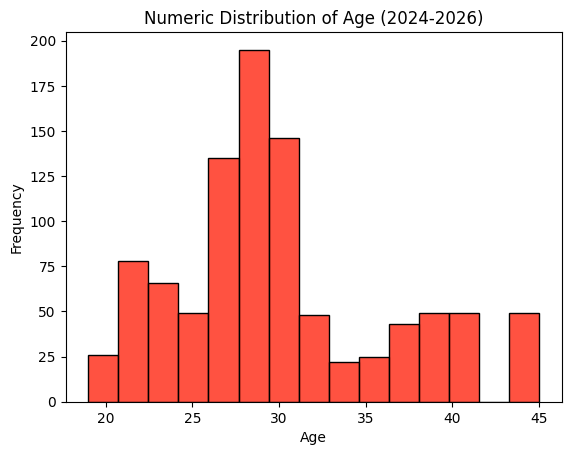

In [3]:
f1_red = '#FF1801'

# Create the histogram
sns.histplot(df['Age'], bins=15, color=f1_red, edgecolor='black')

# Labeling the plot
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Numeric Distribution of Age (2024-2026)')

plt.show()

This figure shows the environmental conditions of each circuit. By mapping circuits with altitude as a size/color dimension, we are showing that environmental conditions vary significantly across each country, which can affect engine performance and aerodynamics.

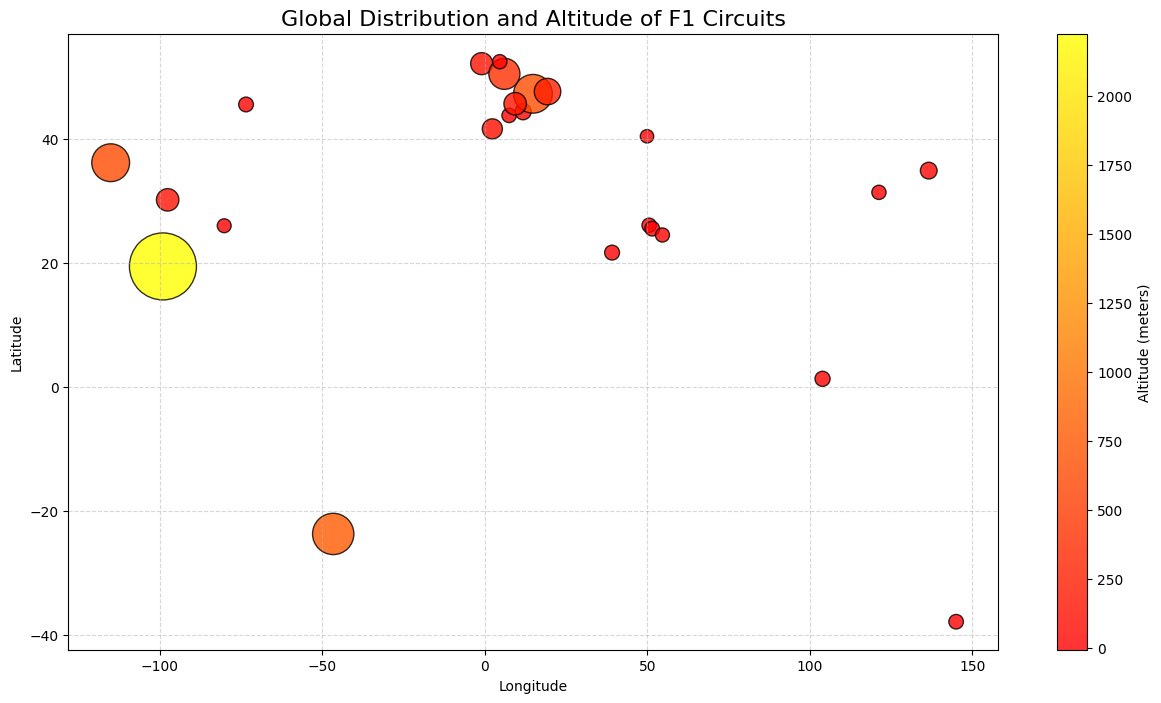

In [4]:
circuits = df[['Circuit', 'Latitude', 'Longitude', 'Altitude (m)']].drop_duplicates()
plt.figure(figsize=(15, 8))

# Scatter plot: 
# s (size) is based on Altitude
# c (color) is based on Altitude using a 'Red/Orange' theme
scatter = plt.scatter(circuits['Longitude'], 
                      circuits['Latitude'], 
                      s=circuits['Altitude (m)'] + 100, 
                      c=circuits['Altitude (m)'], 
                      cmap='autumn', 
                      alpha=0.8, 
                      edgecolors='black')

# Add a color bar to explain the altitude colors
cbar = plt.colorbar(scatter)
cbar.set_label('Altitude (meters)')

# Titles and Labels
plt.title('Global Distribution and Altitude of F1 Circuits', fontsize=16)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

These histograms show the "separation of pace." We used these to observe the variance in lap times as the sessions progress, ensuring the data follows a realistic physical distribution. These show the Q1 Q2 Q3 of each driver before doing any preprocessing functions.

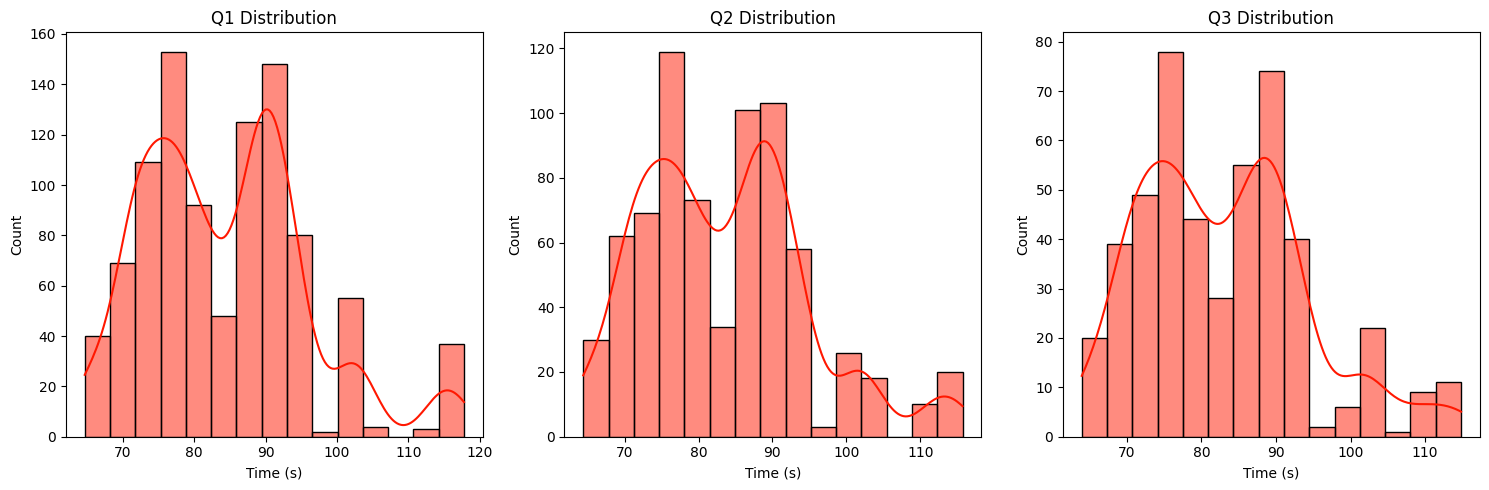

In [5]:
# Qualifying Times Distribution

plt.figure(figsize=(15, 5))

f1_red = '#FF1801'

# 2. Plot Q1 (Position 1 in the 1x3 grid)
plt.subplot(1, 3, 1)
sns.histplot(df['Q1 Time'].dropna(), bins=15, kde=True, color=f1_red)
plt.title('Q1 Distribution')
plt.xlabel('Time (s)')

# 3. Plot Q2 (Position 2 in the 1x3 grid)
plt.subplot(1, 3, 2)
sns.histplot(df['Q2 Time'].dropna(), bins=15, kde=True, color=f1_red)
plt.title('Q2 Distribution')
plt.xlabel('Time (s)')

# 4. Plot Q3 (Position 3 in the 1x3 grid)
plt.subplot(1, 3, 3)
sns.histplot(df['Q3 Time'].dropna(), bins=15, kde=True, color=f1_red)
plt.title('Q3 Distribution')
plt.xlabel('Time (s)')

# Adjust layout to prevent labels from overlapping
plt.tight_layout()
plt.show()

This scatterplot with a regression line showing the raw correlation between starting grid and finishing position.
We can see that the correlation between the starting grid and finishing position is the strongest.

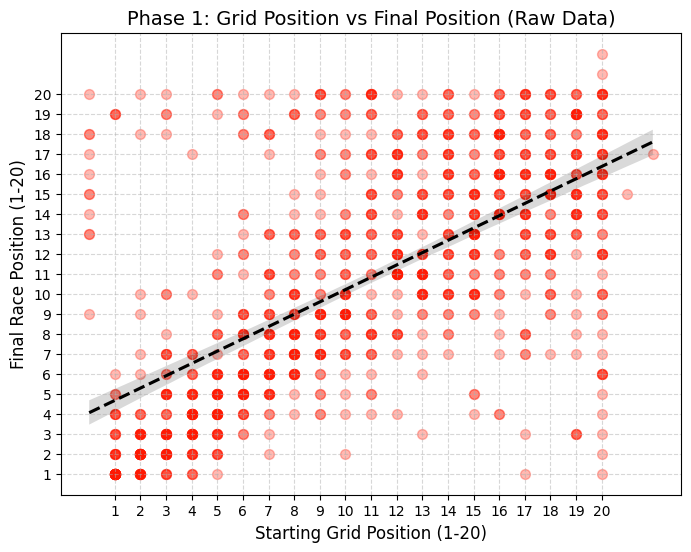

In [6]:
plt.figure(figsize=(8, 6))

# We use 'regplot' to get the scatter points AND the trend line
# s=50 makes the dots bigger, alpha=0.3 helps see overlapping points
sns.regplot(x='Grid Position', y='Final Position', data=df, 
            scatter_kws={'alpha':0.3, 'color':'#FF1801', 's':50}, 
            line_kws={'color':'black', 'linestyle':'--'})

plt.title('Phase 1: Grid Position vs Final Position (Raw Data)', fontsize=14)
plt.xlabel('Starting Grid Position (1-20)', fontsize=12)
plt.ylabel('Final Race Position (1-20)', fontsize=12)
plt.xticks(range(1, 21))
plt.yticks(range(1, 21))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

The constructor boxplot is to analyze the consistency of each constructor's performance. A tight box means the constructor usually finishes around the same position, while a wide box means their performance is more variable. The median line shows the typical finishing position for each constructor, and the whiskers indicate the range of their results. This helps us see which teams are consistently at the front and which ones have more ups and downs.

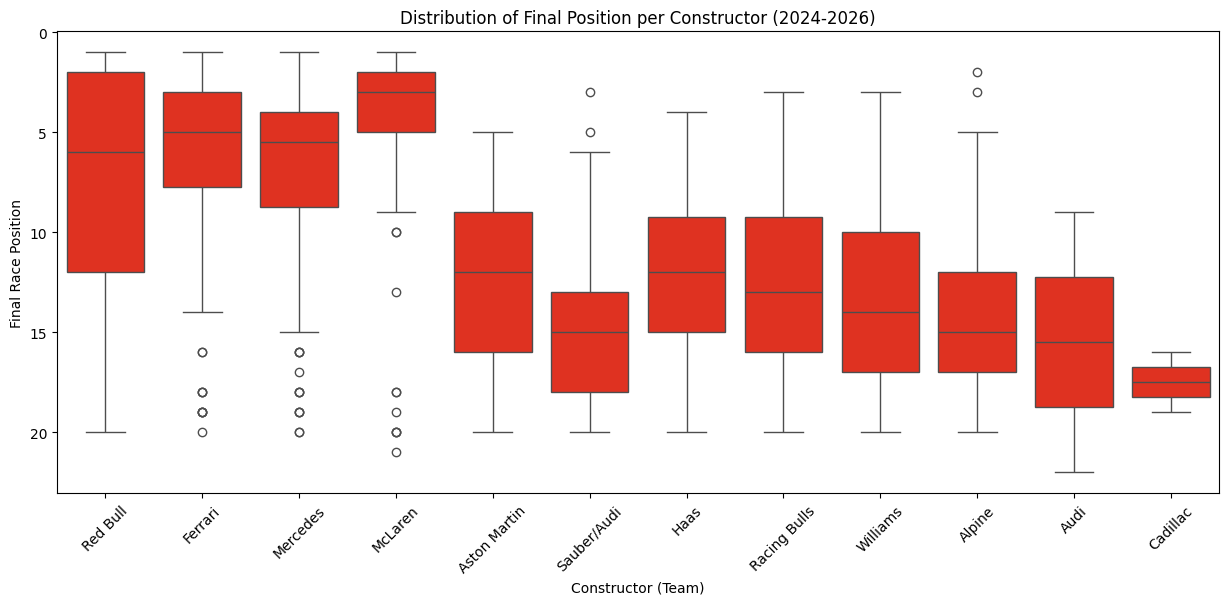

In [7]:
constructor_map = {
    'Haas F1 Team': 'Haas',
    'Alpine F1 Team': 'Alpine',
    'RB F1 Team': 'Racing Bulls',
    'Sauber': 'Sauber/Audi'
}

if 'Constructor' not in df.columns:
    if 'df_model' in globals() and 'df_2026' in globals():
        df = pd.concat([df_model, df_2026], ignore_index=True)
    elif 'df_model' in globals():
        df = df_model.copy()
    else:
        raise KeyError("Constructor column missing and no original race dataset available")

df['Constructor'] = df['Constructor'].replace(constructor_map)

f1_red = '#FF1801'

# Create a wide figure to fit all constructor names
plt.figure(figsize=(15, 6))
sns.boxplot(x='Constructor', y='Final Position', data=df, color=f1_red)
plt.gca().invert_yaxis()

# Add labels and title
plt.title('Distribution of Final Position per Constructor (2024-2026)')
plt.xlabel('Constructor (Team)')
plt.ylabel('Final Race Position')

# Rotate team names for better readability
plt.xticks(rotation=45)
plt.show()

Frequency of the final positions throughout the 2024-2026 seasons. 

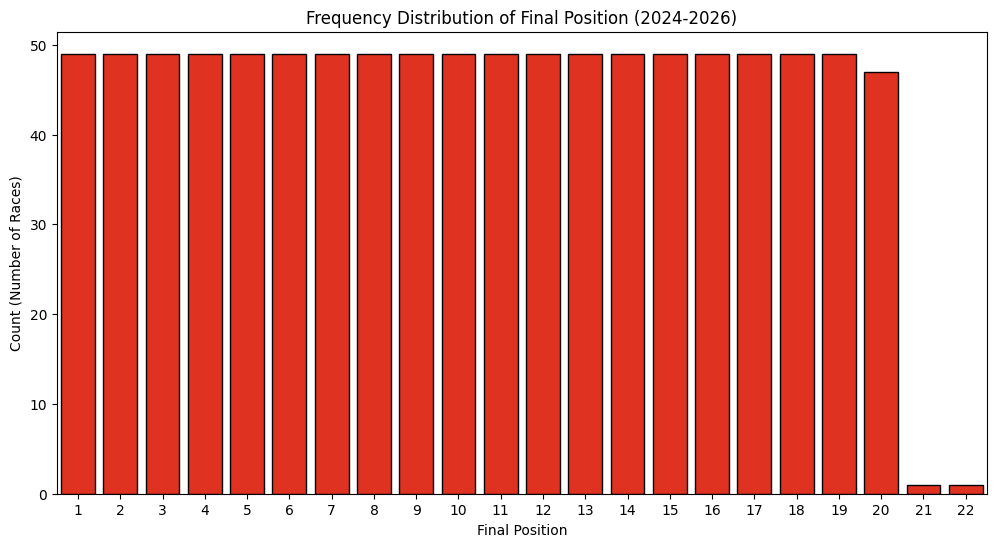

In [8]:
df['Final Position'].value_counts().sort_index()
f1_red = '#FF1801'

# Create the count plot
plt.figure(figsize=(12, 6))
sns.countplot(x='Final Position', data=df, color=f1_red, edgecolor='black')

# Add Labels
plt.title('Frequency Distribution of Final Position (2024-2026)')
plt.xlabel('Final Position')
plt.ylabel('Count (Number of Races)')
plt.show()

Correlation Heatmap between the key features and our target, the final position.

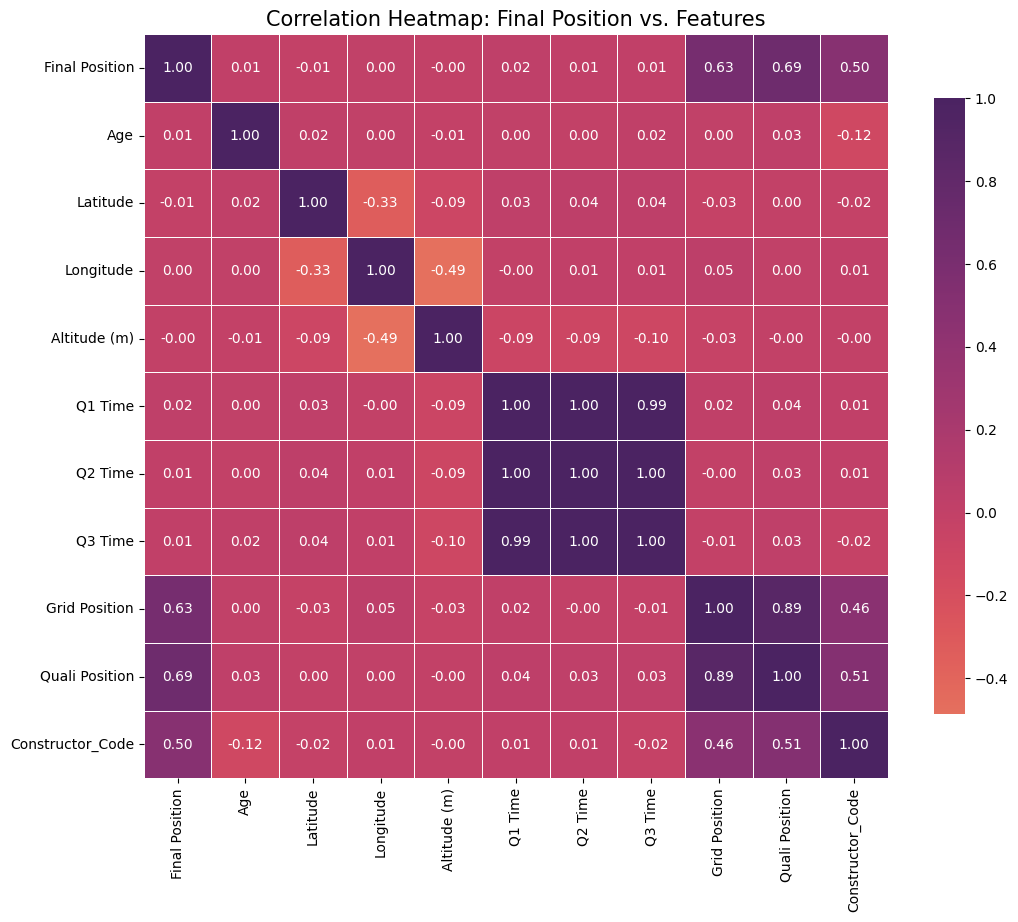

In [9]:
df['Constructor_Code'] = pd.factorize(df['Constructor'])[0]
# List of columns to check
features = [
    'Final Position', 'Age', 
    'Latitude', 'Longitude', 'Altitude (m)', 
    'Q1 Time', 'Q2 Time', 'Q3 Time', 'Grid Position', 'Quali Position',
    'Constructor_Code'
]

# Calculate the correlation matrix
corr_matrix = df[features].corr()
# Set figure size
plt.figure(figsize=(12, 10))

# Create heatmap with annotations (numbers inside the boxes)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="flare", center=0, linewidths=.5, cbar_kws={"shrink": .8}, square=True          
)

# Titles and labels
plt.title('Correlation Heatmap: Final Position vs. Features', fontsize=15)
plt.show()

Our target is the final position, and the frequency distribution shows a balanced dataset across almost all positions, though the inclusion of 2026 data introduces new patterns. We must split the data into training and testing sets to ensure the model learns from past trends (2024–2025) to accurately predict these future 2026 outcomes without simply memorizing the answers

In [10]:
# --- PHASE 2: TEMPORAL SPLIT ---
# Goal: We need to split the data by Year to simulate a real-world scenario.
# We train on 2024, test our accuracy on 2025, and keep 2026 as a "Blind" prediction.

# 1. Isolate the "Future" (2026) immediately
# This data stays in a vault; we don't touch it until the very end.
df_2026 = df[df['Year'] == 2026].copy()

# 2. Create the working dataset for training and testing (2024-2025)
df_model = df[df['Year'] != 2026].copy()

# 3. Define the Target and the "Eraser" list
# We drop 'Year' and 'Date' because they are just markers—not actual performance features.
# We also drop 'Race Name' and 'Circuit' here if we want to rely strictly on numerical stats, 
# but for now, we only drop the essentials to keep the structure clean.
target = 'Final Position'
drop_cols = [target, 'Year', 'Date', 'Race Name','Round']

# 4. Split Train (2024) and Test (2025)
# This mimics a real season-to-season transition.
X_train = df_model[df_model['Year'] == 2024].drop(columns=drop_cols)
y_train = df_model[df_model['Year'] == 2024][target]

X_test = df_model[df_model['Year'] == 2025].drop(columns=drop_cols)
y_test = df_model[df_model['Year'] == 2025][target]

# 5. Prepare the Prediction Features for the 2026 season
# We don't have 'y_predict' because those races haven't happened yet in our simulation!
X_predict = df_2026.drop(columns=drop_cols)

print(f"Training features shape (2024): {X_train.shape}")
print(f"Testing features shape (2025):  {X_test.shape}")
print(f"Prediction features shape (2026): {X_predict.shape}")

Training features shape (2024): (479, 13)
Testing features shape (2025):  (479, 13)
Prediction features shape (2026): (22, 13)


In [11]:
# --- PHASE 3: IMPUTATION (Handling the Holes) ---
# We need to fill the null values so the computer doesn't crash.
# But we have to be smart: a missing Q3 time means the driver was too slow to make it there!

# 1. Handling Qualifying Times (The "Elimination" Penalty)
# Instead of using a random big number like 999, we find the slowest lap 
# in our 2024 training data and add a 10-second penalty. 
# This tells the model: "This driver didn't qualify, they are at the very back."
slowest_q1 = X_train['Q1 Time'].max()
realistic_penalty = slowest_q1 + 10

# We apply this penalty to all qualifying columns
quali_cols = ['Q1 Time', 'Q2 Time', 'Q3 Time']
for col in quali_cols:
    X_train[col] = X_train[col].fillna(realistic_penalty)
    X_test[col] = X_test[col].fillna(realistic_penalty)
    X_predict[col] = X_predict[col].fillna(realistic_penalty)

# 2. Handling Ranking & Position (Median Imputation)
# For things like Quali Position, we use the Median (the middle value).
# This is a safe "normal" value to fill any remaining gaps.
rank_cols = ['Quali Position', 'Grid Position']

for col in rank_cols:
    # IMPORTANT: We calculate the median from the 2024 Train set ONLY 
    # to avoid leaking information from the future (2025/2026).
    col_median = X_train[col].median()
    
    X_train[col] = X_train[col].fillna(col_median)
    X_test[col] = X_test[col].fillna(col_median)
    X_predict[col] = X_predict[col].fillna(col_median)

# 3. Final Null Audit
# Double-checking to make sure every single "hole" is filled.
print("Final Null Audit (Should all be 0):")
print(X_train[quali_cols + rank_cols].isnull().sum())
print(f"\nRealistic Penalty Value used for eliminated drivers: {realistic_penalty:.2f} seconds")

Final Null Audit (Should all be 0):
Q1 Time           0
Q2 Time           0
Q3 Time           0
Quali Position    0
Grid Position     0
dtype: int64

Realistic Penalty Value used for eliminated drivers: 127.78 seconds


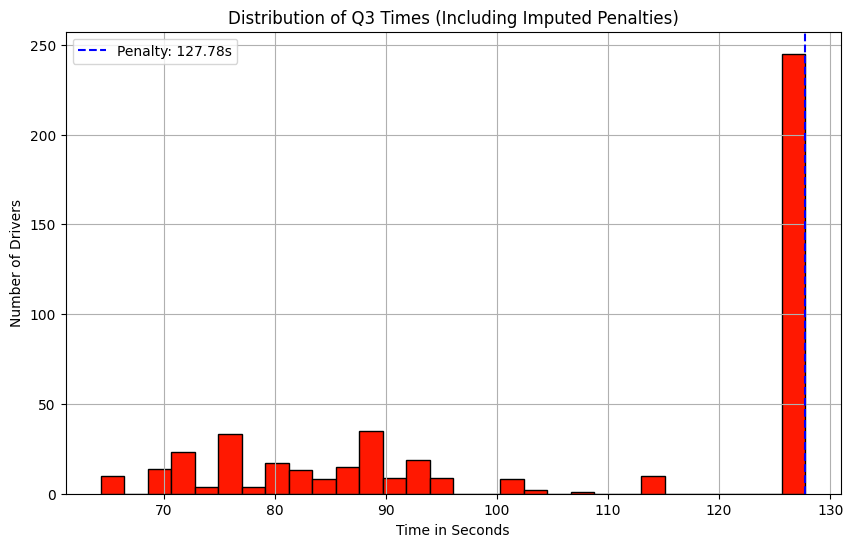

Check the Q3 Time column - you will see the penalty values instead of NaN:
   Q1 Time  Q2 Time  Q3 Time
0   90.031   89.374   89.179
1   90.221   89.932   89.537
2   89.909   89.573   89.507
3   90.243   89.165   89.407
4   90.350   89.922   89.485
5   90.143   89.941   89.614
6   90.451   89.718   89.710
7   90.531   90.122   89.683
8   90.179   89.801   89.542
9   89.965   90.200  127.775


In [12]:

# 1. Visualize the 'Penalty' you created
plt.figure(figsize=(10, 6))
X_train['Q3 Time'].hist(bins=30, color='#FF1801', edgecolor='black')

plt.axvline(realistic_penalty, color='blue', linestyle='--', label=f'Penalty: {realistic_penalty:.2f}s')
plt.title('Distribution of Q3 Times (Including Imputed Penalties)')
plt.xlabel('Time in Seconds')
plt.ylabel('Number of Drivers')
plt.legend()
plt.show()

# 2. Check the first few rows to see the values physically
print("Check the Q3 Time column - you will see the penalty values instead of NaN:")
print(X_train[['Q1 Time', 'Q2 Time', 'Q3 Time']].head(10))

In [13]:
from sklearn.preprocessing import OneHotEncoder

# --- PHASE 4: CATEGORICAL ENCODING ---
# We can't feed names like "Ferrari" into a regression model.
# We need to turn these into numbers without creating a fake "ranking" order.

# 1. Identify the columns we want to encode
# We focus on the most important categories that define the race.
nominal_cols = ['Driver', 'Constructor', 'Circuit']

# 2. Rare Label Encoding (The "Clean-up" Step)
# If a driver or circuit only appears once (maybe a replacement driver), 
# it can make the model unstable. We group these into a "Rare_Label" category.
def handle_rare_labels(df_train, df_test, df_predict, columns, threshold=0.01):
    for col in columns:
        # We find the labels that appear in less than 1% of the training data
        counts = df_train[col].value_counts(normalize=True)
        rare_labels = counts[counts < threshold].index
        
        # We replace them across all sets to keep everything consistent
        df_train[col] = df_train[col].replace(rare_labels, 'Rare_Label')
        df_test[col] = df_test[col].replace(rare_labels, 'Rare_Label')
        df_predict[col] = df_predict[col].replace(rare_labels, 'Rare_Label')
    return df_train, df_test, df_predict

X_train, X_test, X_predict = handle_rare_labels(X_train, X_test, X_predict, nominal_cols)

# 3. One-Hot Encoding
# This creates a new column for every Driver/Team with a 1 or 0.
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# We fit the encoder ONLY on the 2024 Train set (The Golden Rule)
ohe.fit(X_train[nominal_cols])

def apply_ohe_safe(df_set, encoder, columns):
    # Transform the text columns into a matrix of 1s and 0s
    encoded_array = encoder.transform(df_set[columns])
    
    # Create a new DataFrame with clear column names (e.g., 'Driver_Max Verstappen')
    encoded_df = pd.DataFrame(
        encoded_array, 
        columns=encoder.get_feature_names_out(columns), 
        index=df_set.index
    )
    
    # Drop the original text columns and attach the new 1/0 columns
    return pd.concat([df_set.drop(columns=columns), encoded_df], axis=1)

# Apply the transformation to all our sets
X_train = apply_ohe_safe(X_train, ohe, nominal_cols)
X_test = apply_ohe_safe(X_test, ohe, nominal_cols)
X_predict = apply_ohe_safe(X_predict, ohe, nominal_cols)

print(f"Encoding Finished!")
print(f"New feature count: {X_train.shape[1]} columns")

Encoding Finished!
New feature count: 67 columns


In [14]:
from sklearn.preprocessing import StandardScaler

# --- PHASE 5: FEATURE SCALING (The Fixed Version) ---
# We need to scale our numbers, but we have to make sure we don't 
# call columns we dropped in Phase 1 (like Fastest Lap Speed).

# 1. Define only the columns that actually exist in our X_train now
# These are the ones that survived the Phase 1 cleanup.
available_numeric = [
    'Q1 Time', 'Q2 Time', 'Q3 Time', 'Quali Position', 'Grid Position'
]

# 2. Safety Check: Filter the list just in case
numeric_features = [col for col in available_numeric if col in X_train.columns]

# 3. Initialize and Fit
scaler = StandardScaler()
scaler.fit(X_train[numeric_features])

# 4. Transform
X_train[numeric_features] = scaler.transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])
X_predict[numeric_features] = scaler.transform(X_predict[numeric_features])

print(f"Successfully scaled: {numeric_features}")

Successfully scaled: ['Q1 Time', 'Q2 Time', 'Q3 Time', 'Quali Position', 'Grid Position']


In [15]:
df = pd.read_excel(r"X_train_preprocessed.xlsx")


In [16]:
df.head()


,Latitude,Longitude,Altitude (m),Grid Position,Quali Position,Q1 Time,Q2 Time,Q3 Time,Age,Driver_Alexander Albon,...,Circuit_Jeddah Corniche Circuit,Circuit_Las Vegas Strip Street Circuit,Circuit_Losail International Circuit,Circuit_Marina Bay Street Circuit,Circuit_Miami International Autodrome,Circuit_Red Bull Ring,Circuit_Shanghai International Circuit,Circuit_Silverstone Circuit,Circuit_Suzuka Circuit,Circuit_Yas Marina Circuit
0,26.0325,50.5106,7,-1.561060,-1.647029,0.379040,-0.276997,-0.733591,29,0,...,0,0,0,0,0,0,0,0,0,0
1,26.0325,50.5106,7,-0.869022,-0.952092,0.395042,-0.250767,-0.718244,36,0,...,0,0,0,0,0,0,0,0,0,0
2,26.0325,50.5106,7,-1.042031,-1.125827,0.368766,-0.267643,-0.719530,32,0,...,0,0,0,0,0,0,0,0,0,0
3,26.0325,50.5106,7,-1.388051,-1.473295,0.396894,-0.286822,-0.723817,29,0,...,0,0,0,0,0,0,0,0,0,0
4,26.0325,50.5106,7,-1.215041,-1.299561,0.405906,-0.251237,-0.720473,28,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
df = pd.read_excel(r"X_test_preprocessed.xlsx")

In [18]:
df.head()

,Latitude,Longitude,Altitude (m),Grid Position,Quali Position,Q1 Time,Q2 Time,Q3 Time,Age,Driver_Alexander Albon,...,Circuit_Jeddah Corniche Circuit,Circuit_Las Vegas Strip Street Circuit,Circuit_Losail International Circuit,Circuit_Marina Bay Street Circuit,Circuit_Miami International Autodrome,Circuit_Red Bull Ring,Circuit_Shanghai International Circuit,Circuit_Silverstone Circuit,Circuit_Suzuka Circuit,Circuit_Yas Marina Circuit
0,-37.8497,144.968,10,-1.561060,-1.647029,-0.810032,-0.933175,-1.337323,27,0,...,0,0,0,0,0,0,0,0,0,0
1,-37.8497,144.968,10,-1.215041,-1.299561,-0.801105,-0.926123,-1.320818,29,0,...,0,0,0,0,0,0,0,0,0,0
2,-37.8497,144.968,10,-1.042031,-1.125827,-0.805063,-0.915171,-1.318032,28,0,...,0,0,0,0,0,0,0,0,0,0
3,-37.8497,144.968,10,1.034085,0.958984,-0.758406,1.528137,0.921003,20,0,...,0,0,0,0,0,0,0,0,0,0
4,-37.8497,144.968,10,-0.696012,-0.778358,-0.781987,-0.904876,-1.309844,30,1,...,0,0,0,0,0,0,0,0,0,0


These kdeplots compares the distribution of scaled qualifying times between the train and test sets.

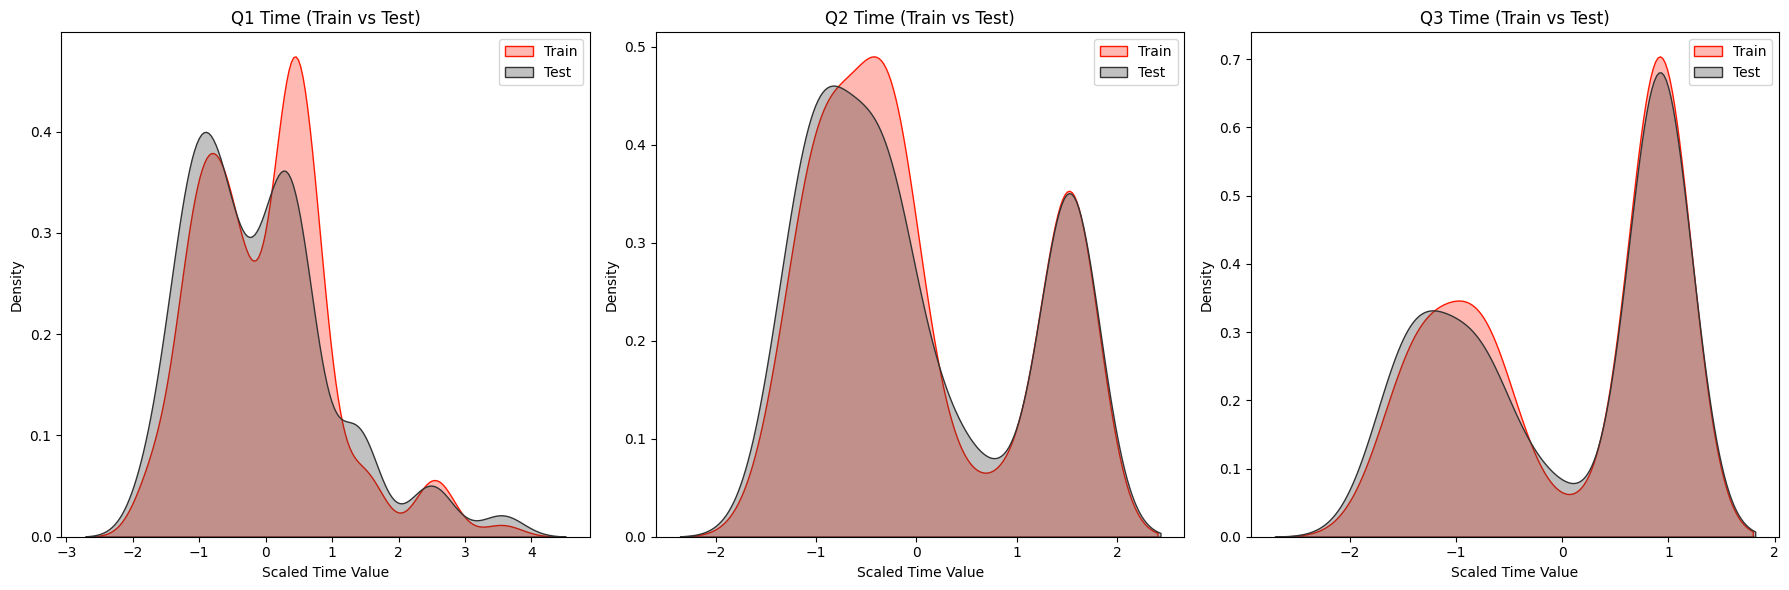

In [19]:
plt.figure(figsize=(18, 6))
f1_red = '#FF1801'
grey_test = '#333333'

# Create three subplots for Q1, Q2, and Q3
sessions = ['Q1 Time', 'Q2 Time', 'Q3 Time']

for i, session in enumerate(sessions, 1):
    plt.subplot(1, 3, i)
    sns.kdeplot(X_train[session], color=f1_red, label='Train', fill=True, alpha=0.3)
    sns.kdeplot(X_test[session], color=grey_test, label='Test', fill=True, alpha=0.3)
    plt.title(f'{session} (Train vs Test)')
    plt.xlabel('Scaled Time Value')
    plt.legend()

plt.tight_layout()
plt.show()

In [20]:
df = pd.read_excel(r"y_train.xlsx")
df = pd.read_excel(r"y_test.xlsx")

Side by side regression plots after scaling. We can that the correlation between the 2 is consistent.

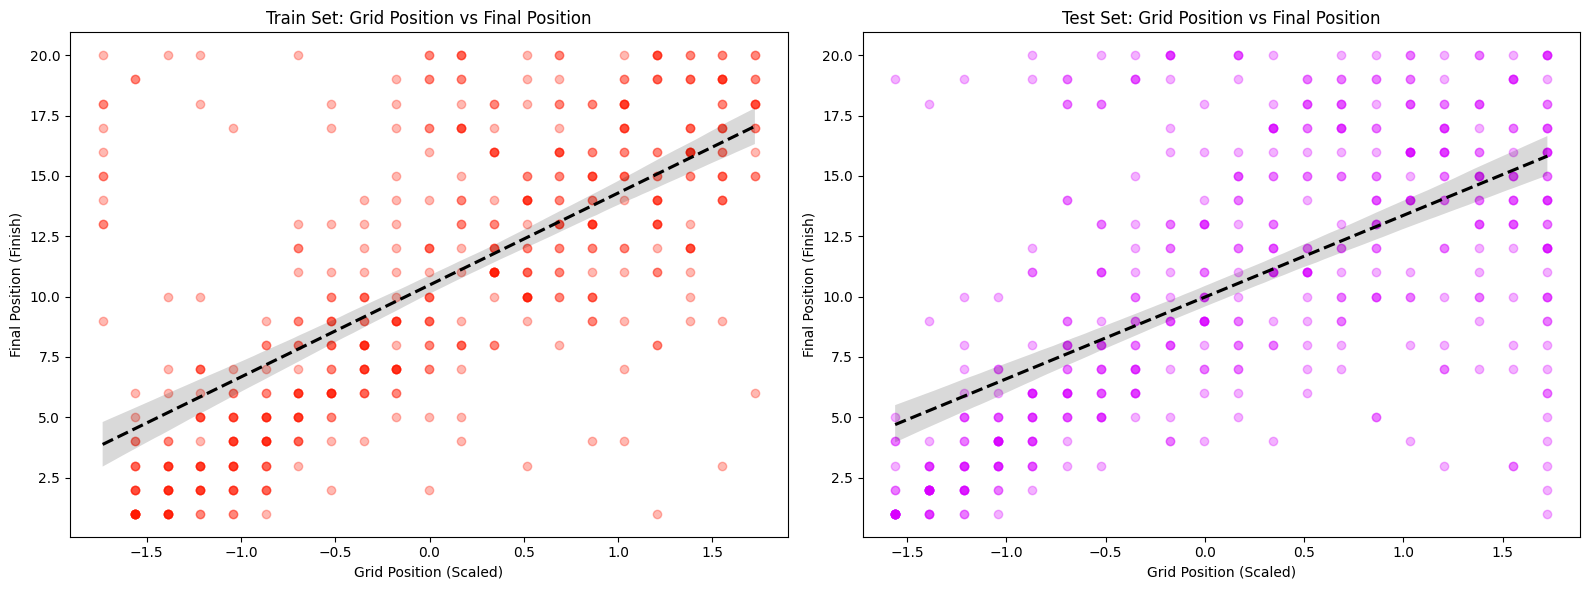

In [21]:
X_train_df = X_train.copy()
X_train_df['Final Position'] = y_train

X_test_df = X_test.copy()
X_test_df['Final Position'] = y_test

# 3. Now run your plotting code
plt.figure(figsize=(16, 6))
f1_red = '#FF1801'
grey_test = "#D900FF"
# Subplot 1: Training Set
plt.subplot(1, 2, 1)
sns.regplot(x='Grid Position', y='Final Position', data=X_train_df, 
            scatter_kws={'alpha':0.3, 'color':f1_red}, 
            line_kws={'color':'black', 'linestyle':'--'})
plt.title('Train Set: Grid Position vs Final Position')
plt.xlabel('Grid Position (Scaled)')
plt.ylabel('Final Position (Finish)')

# Subplot 2: Testing Set
plt.subplot(1, 2, 2)
sns.regplot(x='Grid Position', y='Final Position', data=X_test_df, 
            scatter_kws={'alpha':0.3, 'color':grey_test}, 
            line_kws={'color':'black', 'linestyle':'--'})
plt.title('Test Set: Grid Position vs Final Position')
plt.xlabel('Grid Position (Scaled)')
plt.ylabel('Final Position (Finish)')

plt.tight_layout()
plt.show()

Correlation heatmap after the preprocessing functions were made. Notice how the Qualifying Times are now more correlated with Final Position, and the Grid Position has a stronger relationship as well. This is a good sign that our preprocessing steps have made the data more meaningful for modeling!

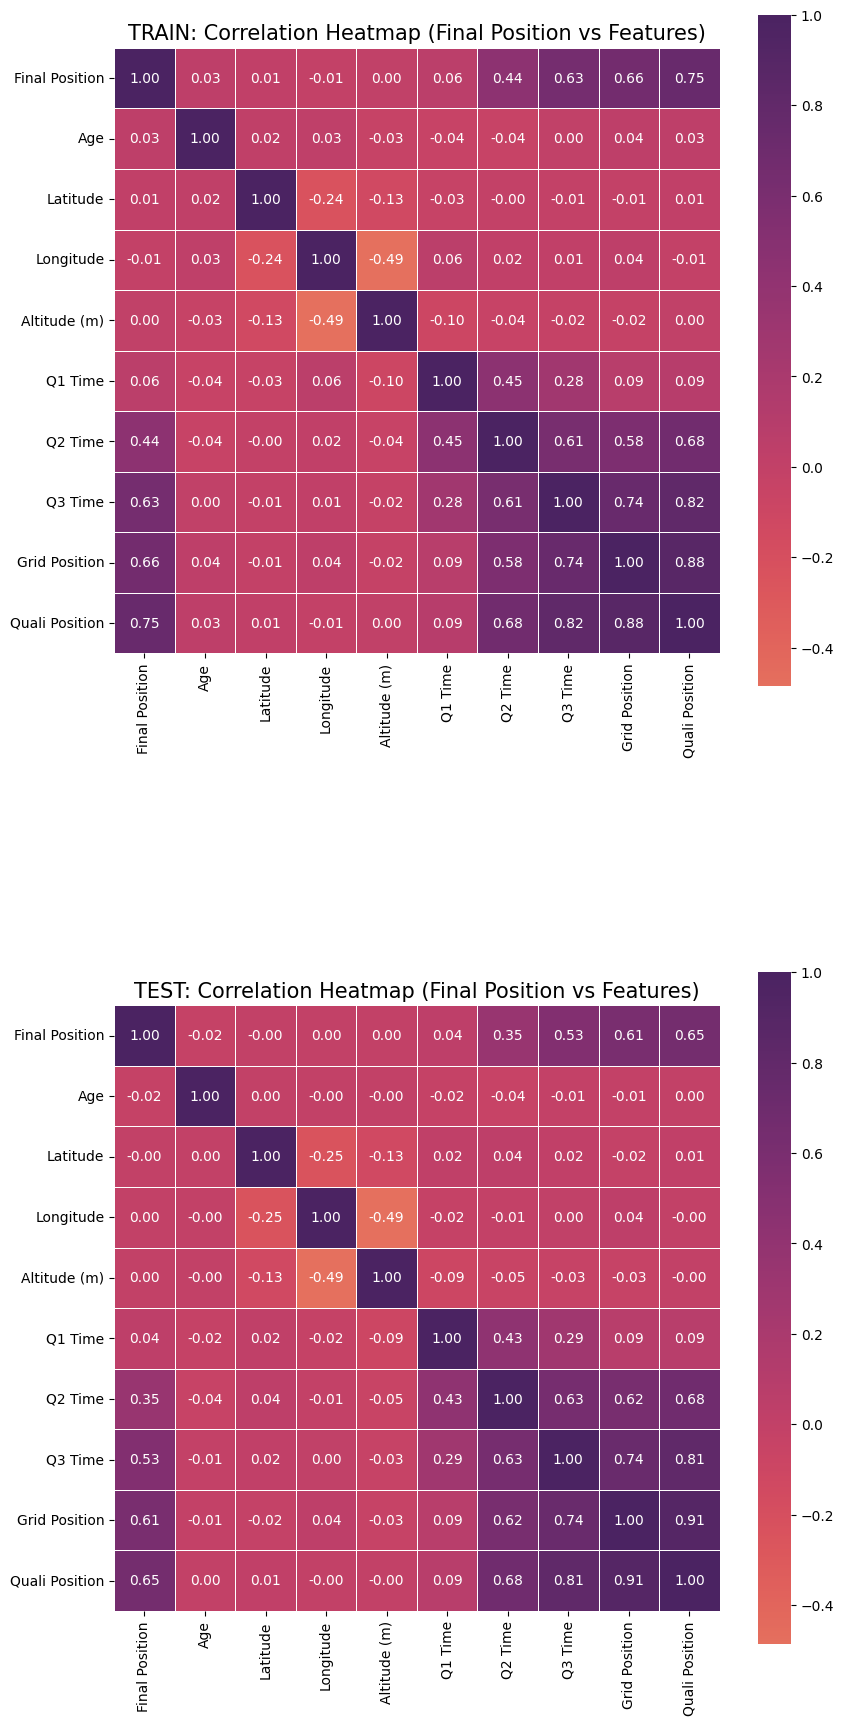

In [22]:
features = [
    'Final Position', 'Age', 
    'Latitude', 'Longitude', 'Altitude (m)', 
    'Q1 Time', 'Q2 Time', 'Q3 Time', 'Grid Position', 'Quali Position'
]

# 3. Set up the figure with 2 rows and 1 column
# We increase the height (22) so they don't look squashed
plt.figure(figsize=(10, 20))

# --- Top Plot: Train Set ---
plt.subplot(2, 1, 1)
corr_matrix_train = X_train_df[features].corr()
sns.heatmap(corr_matrix_train, annot=True, fmt=".2f", cmap="flare", center=0, 
            linewidths=.5, cbar_kws={"shrink": .8}, square=True)
plt.title('TRAIN: Correlation Heatmap (Final Position vs Features)', fontsize=15)

# --- Bottom Plot: Test Set ---
plt.subplot(2, 1, 2)
corr_matrix_test = X_test_df[features].corr()
sns.heatmap(corr_matrix_test, annot=True, fmt=".2f", cmap="flare", center=0, 
            linewidths=.5, cbar_kws={"shrink": .8}, square=True)
plt.title('TEST: Correlation Heatmap (Final Position vs Features)', fontsize=15)

# 4. Use tight_layout with padding to prevent the title of the bottom plot 
# from overlapping with the top plot.
plt.tight_layout(pad=5.0)
plt.show()

Anomaly Detection:
 Before training the final model, we check whether the training data containsany statistical outliers that could mislead the model. We first compare multiple anomaly detection algorithms to select the best one, then apply it to clean the training data.

In [35]:

%pip install pyod

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from pyod.models.knn import KNN
from pyod.models.hbos import HBOS
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import classification_report, confusion_matrix


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 446.7 kB/s eta 0:00:05
   ------- -------------------------------- 0.5/2.8 MB 446.7 kB/s eta 0:00:05
   ------- -------------------------------- 0.5/2.8 MB 446.7 kB/s eta 0:00:05
   ----------- ---------------------------- 0.8/2.8 MB 418.5 kB/s eta 0:00:05
   ----------- ---------------------------- 0.8/2.8 MB 418.5 kB/s eta 0:00:05
   ----------- ---------------------------- 0.8/2.8 MB 418.5 kB/s eta 0:00:05
   --------------- ------------------------ 1.0/2.8 MB 444.2 kB/s eta 0:00:04
   --------------- ------------------------ 1.0/2.8 MB 444.2 kB/s eta 0:00:04
   ------------------- --------

In [25]:
# Use the numeric features from your F1 training data for the comparison
numeric_cols = ['Grid Position', 'Quali Position', 'Q1 Time', 'Q2 Time', 'Q3 Time',
                'Age', 'Latitude', 'Longitude', 'Altitude (m)']

data_scaled = X_train[numeric_cols].values

# Inject 50 synthetic anomalies to give each algorithm a ground truth to evaluate against
np.random.seed(42)
anomalies = np.random.uniform(low=-6, high=6, size=(50, data_scaled.shape[1]))
data_with_anomalies = np.vstack([data_scaled, anomalies])
labels = np.hstack([np.zeros(data_scaled.shape[0]), np.ones(50)])

In [26]:
# Visualization helper function
def visualize_outliers(method_name, preds, labels, title_suffix=''):
    plt.figure(figsize=(8, 6))
    plt.scatter(data_with_anomalies[:, 0], data_with_anomalies[:, 1], c=preds, cmap='flare', edgecolors='k')
    plt.title(f'{method_name} - {title_suffix}')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.colorbar(label='Anomaly Score')
    plt.show()


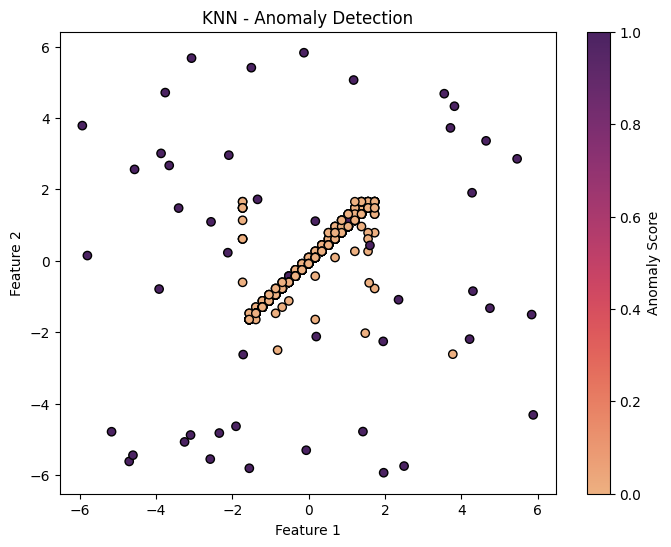

In [36]:
# 1. KNN
knn = KNN(n_neighbors=5, method='largest')
knn.fit(data_with_anomalies)
knn_preds = knn.labels_  # binary labels (0: normal, 1: outlier)
visualize_outliers('KNN', knn_preds, labels, 'Anomaly Detection')


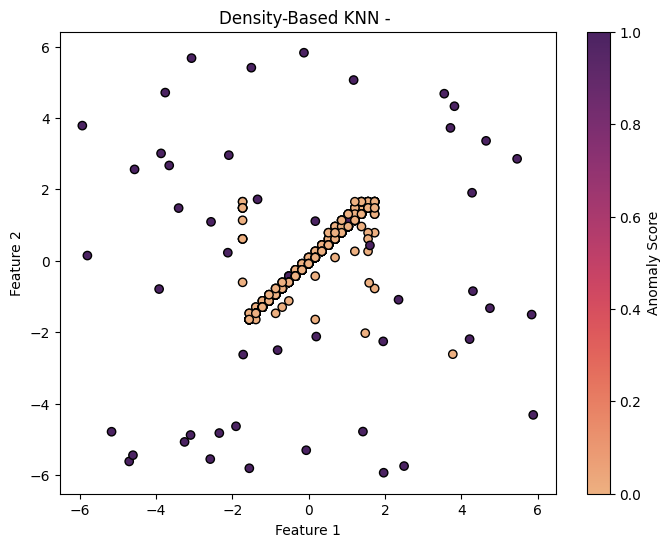

In [37]:
# 2. Density-Based KNN
knn_density = KNN(n_neighbors=5, method='mean')
knn_density.fit(data_with_anomalies)
knn_density_preds = knn_density.labels_
visualize_outliers('Density-Based KNN', knn_density_preds, labels)

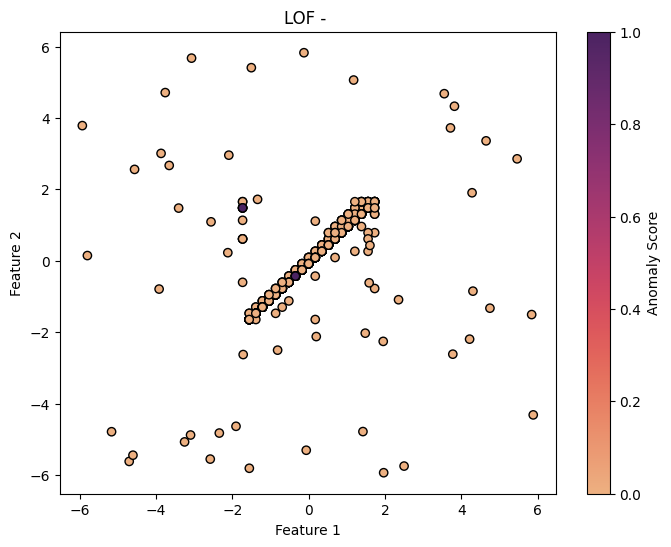

In [29]:
# 3. Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_preds = lof.fit_predict(data_with_anomalies)
lof_preds = np.where(lof_preds == 1, 0, 1)  # Invert labels to match anomaly labeling
visualize_outliers('LOF', lof_preds, labels)

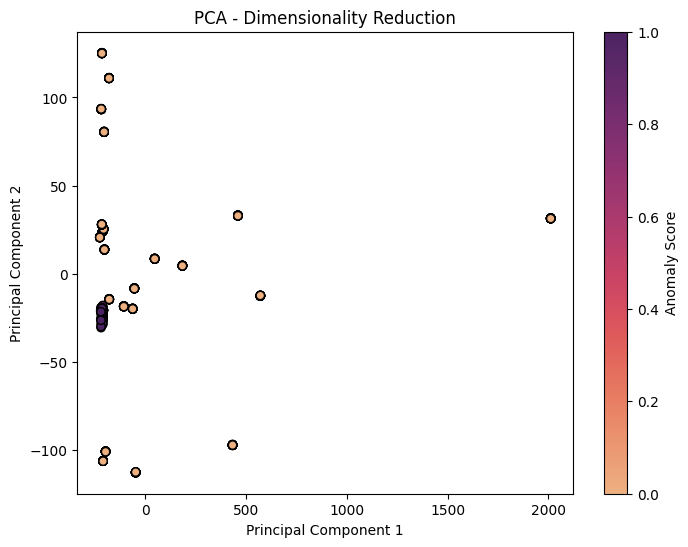

In [30]:
# 4. PCA
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_with_anomalies)
plt.figure(figsize=(8, 6))
plt.scatter(data_pca[:, 0], data_pca[:, 1], c=labels, cmap='flare', edgecolors='k')
plt.title('PCA - Dimensionality Reduction')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Anomaly Score')
plt.show()

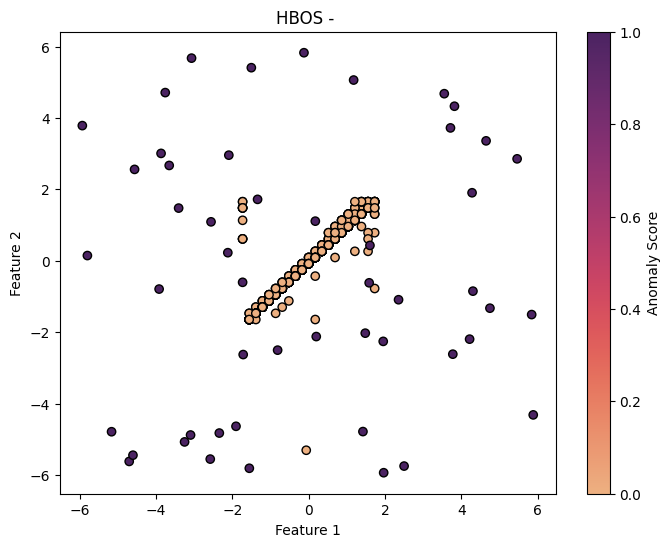

In [38]:
# 5. HBOS
hbos = HBOS()
hbos.fit(data_with_anomalies)
hbos_preds = hbos.labels_
visualize_outliers('HBOS', hbos_preds, labels)

c:\Users\Administrator\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


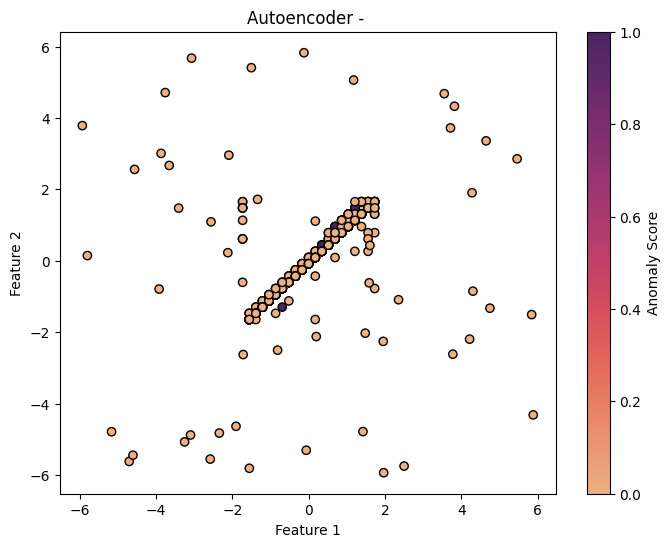

In [39]:
# 6. Autoencoders using MLPRegressor
input_dim = data_with_anomalies.shape[1]

autoencoder = MLPRegressor(hidden_layer_sizes=(14, 7, 14), activation='relu', max_iter=200, random_state=42)
autoencoder.fit(data_with_anomalies, data_with_anomalies)

reconstructions = autoencoder.predict(data_with_anomalies)
mse = np.mean(np.power(data_with_anomalies - reconstructions, 2), axis=1)
threshold = np.percentile(mse, 95)
autoencoder_preds = (mse > threshold).astype(int)
visualize_outliers('Autoencoder', autoencoder_preds, labels)

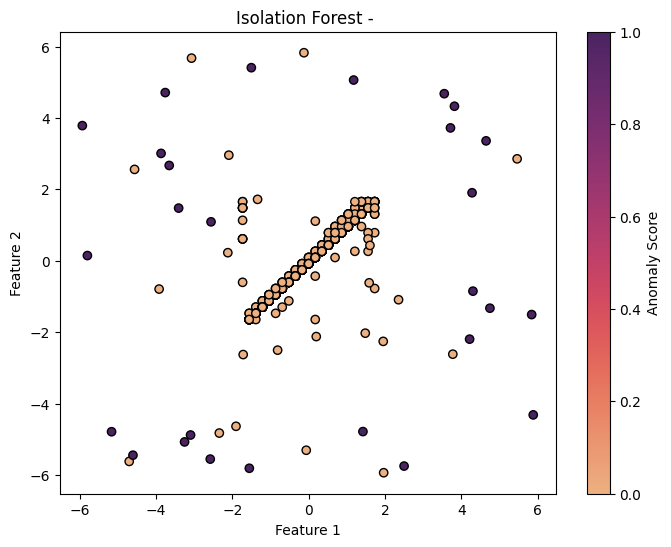

In [40]:
# 7. Isolation Forest
iso_forest = IsolationForest(contamination=0.05)
iso_forest.fit(data_with_anomalies)
iso_preds = iso_forest.predict(data_with_anomalies)
iso_preds = np.where(iso_preds == 1, 0, 1)
visualize_outliers('Isolation Forest', iso_preds, labels)

In [41]:
# Calculate the number of correct predictions per algorithm
results = pd.DataFrame({
    'Method': ['KNN', 'Density KNN', 'LOF', 'HBOS', 'Autoencoder', 'Isolation Forest'],
    'Correct Predictions': [
        np.sum(knn_preds == labels),
        np.sum(knn_density_preds == labels),
        np.sum(lof_preds == labels),
        np.sum(hbos_preds == labels),
        np.sum(autoencoder_preds == labels),
        np.sum(iso_preds == labels)
    ]
})
print(results)


             Method  Correct Predictions
0               KNN                  518
1       Density KNN                  520
2               LOF                  452
3              HBOS                  524
4       Autoencoder                  452
5  Isolation Forest                  506


In [42]:
# Step 1: Baseline Model without Anomaly Detection
clf_baseline = RandomForestClassifier(random_state=42)
clf_baseline.fit(X_train, y_train)
y_pred_baseline = clf_baseline.predict(X_test)
accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
print("Baseline Accuracy without Anomaly Detection:", accuracy_baseline)
print(classification_report(y_test, y_pred_baseline))


Baseline Accuracy without Anomaly Detection: 0.13987473903966596
              precision    recall  f1-score   support

           1       0.46      0.50      0.48        24
           2       0.30      0.29      0.30        24
           3       0.17      0.17      0.17        24
           4       0.17      0.21      0.19        24
           5       0.22      0.21      0.21        24
           6       0.11      0.08      0.10        24
           7       0.13      0.17      0.15        24
           8       0.06      0.08      0.07        24
           9       0.09      0.12      0.10        24
          10       0.07      0.08      0.08        24
          11       0.13      0.12      0.13        24
          12       0.08      0.08      0.08        24
          13       0.00      0.00      0.00        24
          14       0.09      0.08      0.09        24
          15       0.00      0.00      0.00        24
          16       0.20      0.17      0.18        24
          17    

In [43]:
# Step 2: Anomaly Detection with HBO

numeric_cols = ['Grid Position', 'Quali Position', 'Q1 Time', 'Q2 Time', 'Q3 Time',
                'Age', 'Latitude', 'Longitude', 'Altitude (m)']

# Step 2: HBOS
hbos_detector = HBOS(contamination=0.05)
hbos_detector.fit(X_train[numeric_cols])
train_anomalies = np.where(hbos_detector.labels_ == 0, 1, -1)

# Save filtered as NEW variable — don't touch X_train
X_train_filtered = X_train[train_anomalies == 1]
y_train_filtered = y_train[train_anomalies == 1]

print(np.sum(train_anomalies == -1))

24


In [44]:
# Step 3
clf_filtered = RandomForestClassifier(random_state=42)
clf_filtered.fit(X_train_filtered, y_train_filtered)
y_pred_filtered = clf_filtered.predict(X_test)
accuracy_filtered = accuracy_score(y_test, y_pred_filtered)

The bar chart shows that the before anomaly detection, the accuracy was higher.

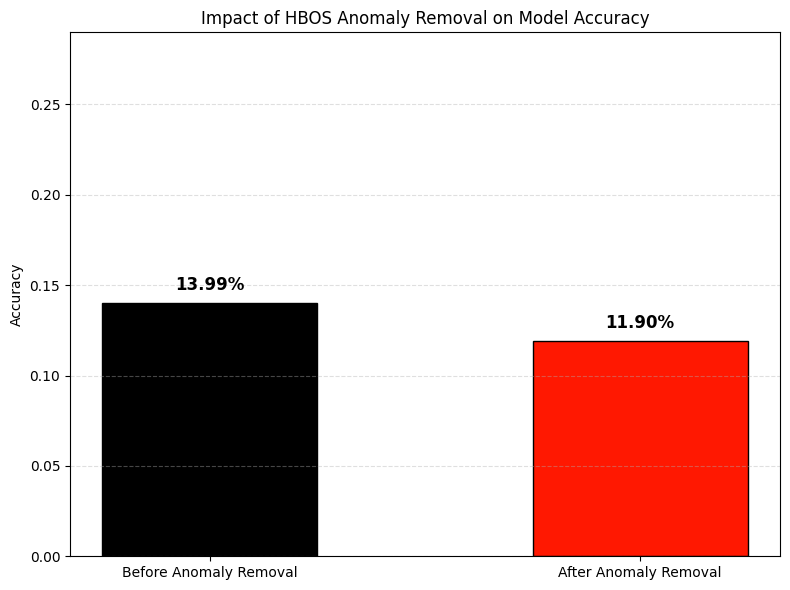

In [45]:
# Bar chart
plt.figure(figsize=(8, 6))
f1_dark = '#000000'
f1_red = '#FF1801'

bars = plt.bar(
    ['Before Anomaly Removal', 'After Anomaly Removal'],
    [accuracy_baseline, accuracy_filtered],
    color=[f1_dark, f1_red], edgecolor='black', width=0.5
)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.005,
             f'{height:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy')
plt.title('Impact of HBOS Anomaly Removal on Model Accuracy')
plt.ylim(0, max(accuracy_baseline, accuracy_filtered) + 0.15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Boxplot showing the distribution of Grid Position and Quali Position for normal vs anomalous rows. Anomalous rows tend to have more extremeposition values confirming HBOS correctly flagged statistical outliers.

The anomaly box is very tight and sits around -0.5, meaning anomalous rows all have very similar qualifying positions clustered near the front.

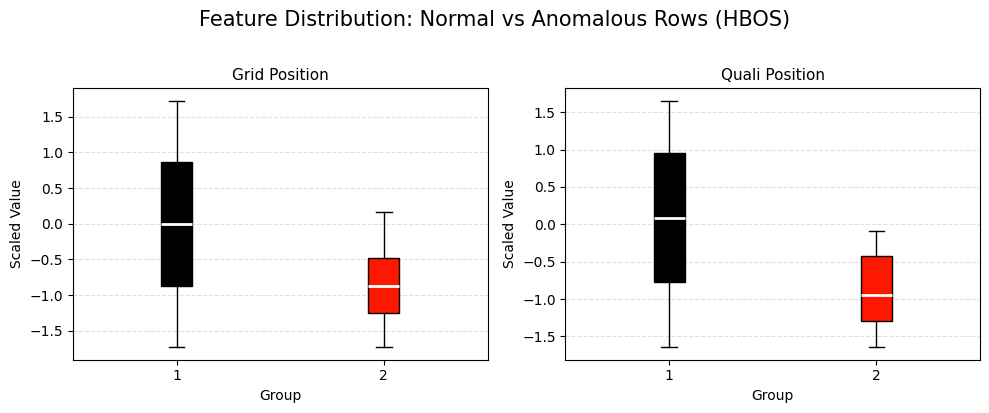

In [46]:
# Boxplot
X_train['Anomaly'] = train_anomalies

features_to_show = ['Grid Position', 'Quali Position']
fig, axes = plt.subplots(1, len(features_to_show), figsize=(10, 4))

for ax, feature in zip(axes, features_to_show):
    data_to_plot = [
        X_train.loc[X_train['Anomaly'] == 1, feature].values,
        X_train.loc[X_train['Anomaly'] == -1, feature].values
    ]
    bp = ax.boxplot(data_to_plot, patch_artist=True,
                    whiskerprops=dict(color='black', linewidth=1),
                    capprops=dict(color='black', linewidth=1),
                    medianprops=dict(color='white', linewidth=2))
    bp['boxes'][0].set_facecolor(f1_dark)
    bp['boxes'][1].set_facecolor(f1_red)
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel('Group')
    ax.set_ylabel('Scaled Value')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Feature Distribution: Normal vs Anomalous Rows (HBOS)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

Density plot showing where anomalies fall in the qualifying time distributions. The red peaks reveal the imputed penalty values (drivers who didn't qualify)

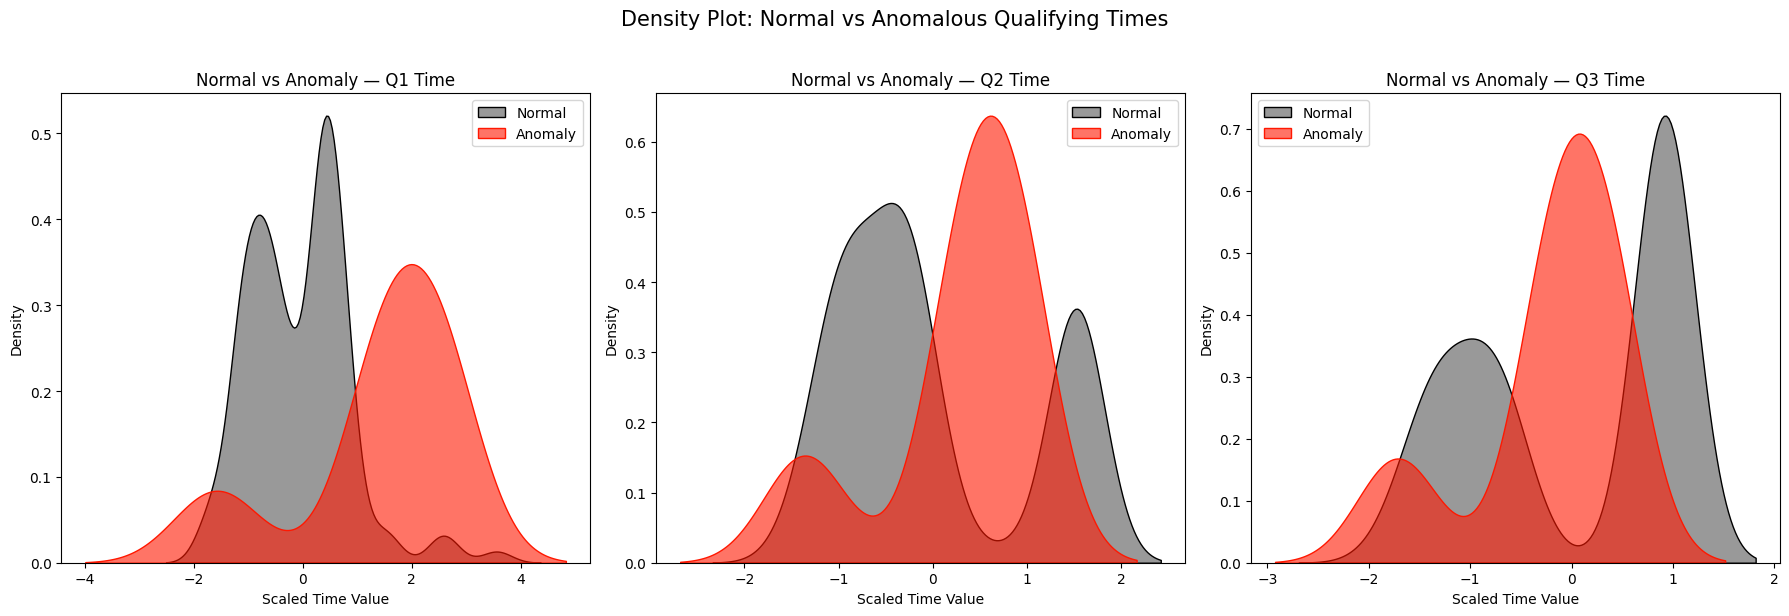

In [47]:
# Density plot
X_train['Anomaly'] = train_anomalies
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, session in zip(axes, ['Q1 Time', 'Q2 Time', 'Q3 Time']):
    sns.kdeplot(X_train.loc[X_train['Anomaly'] == 1, session],
                label='Normal', fill=True, color=f1_dark, alpha=0.4, ax=ax)
    sns.kdeplot(X_train.loc[X_train['Anomaly'] == -1, session],
                label='Anomaly', fill=True, color=f1_red, alpha=0.6, ax=ax)
    ax.set_title(f'Normal vs Anomaly — {session}')
    ax.set_xlabel('Scaled Time Value')
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Density Plot: Normal vs Anomalous Qualifying Times', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

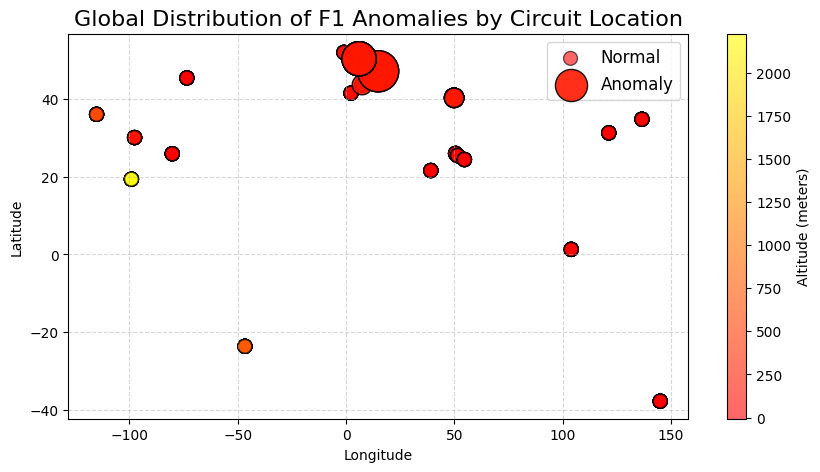

In [48]:
# Scatter plot of anomalies
plt.figure(figsize=(10, 5))

# Normal points
normal_mask = X_train['Anomaly'] == 1
scatter_normal = plt.scatter(
    X_train.loc[normal_mask, 'Longitude'],
    X_train.loc[normal_mask, 'Latitude'],
    s=100,
    c=X_train.loc[normal_mask, 'Altitude (m)'],
    cmap='autumn',
    alpha=0.6,
    edgecolors='black',
    label='Normal'
)

# Anomaly points — larger and red so they stand out
anomaly_mask = X_train['Anomaly'] == -1
plt.scatter(
    X_train.loc[anomaly_mask, 'Longitude'],
    X_train.loc[anomaly_mask, 'Latitude'],
    s=X_train.loc[anomaly_mask, 'Altitude (m)'] + 200,
    c='#FF1801',
    alpha=0.9,
    edgecolors='black',
    label='Anomaly',
    zorder=5  # draws anomalies on top
)

# Colorbar for altitude
cbar = plt.colorbar(scatter_normal)
cbar.set_label('Altitude (meters)')

plt.title('Global Distribution of F1 Anomalies by Circuit Location', fontsize=16)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Correlation heatmap including the Anomaly column.
The heatmap reveals that HBOS flags drivers at both extremes of the field, those with unusually fast Q1 times and those starting from the back, while confirming expected F1 patterns such as the strong link between qualifying and grid position

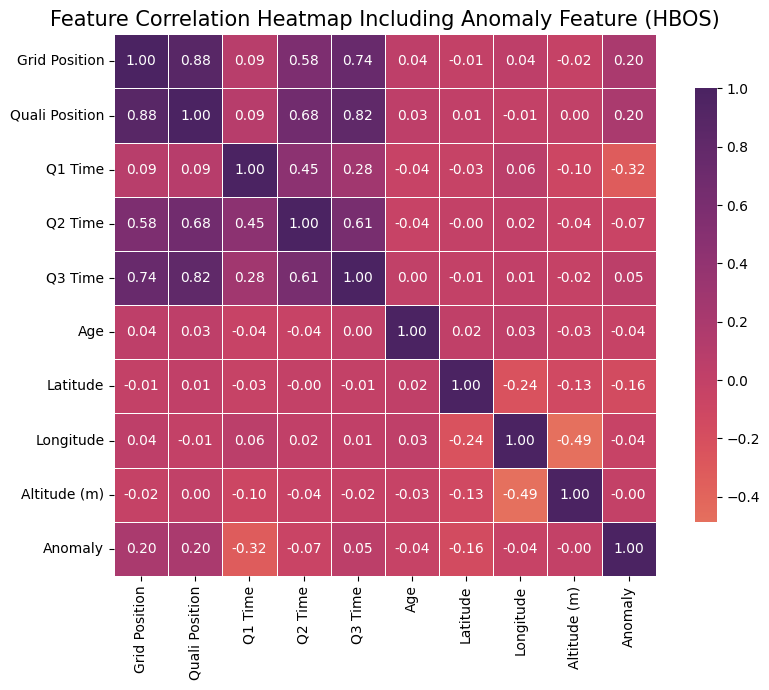

In [49]:
# Add anomaly labels
X_train['Anomaly'] = train_anomalies

# Heatmap
features_anomaly = [
    'Grid Position', 'Quali Position', 'Q1 Time', 'Q2 Time', 'Q3 Time',
    'Age', 'Latitude', 'Longitude', 'Altitude (m)', 'Anomaly'
]
features_anomaly = [f for f in features_anomaly if f in X_train.columns]

plt.figure(figsize=(9, 7))
sns.heatmap(
    X_train[features_anomaly].corr(),
    annot=True, fmt='.2f',
    cmap='flare', center=0,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    square=True
)
plt.title('Feature Correlation Heatmap Including Anomaly Feature (HBOS)', fontsize=15)
plt.tight_layout()
plt.show()

Trying another anomaly detector: Isolation Forest

In [50]:
# --- Clean up the Anomaly column HBOS left behind ---
# The HBOS section above added an 'Anomaly' column to X_train.
# We must remove it before fitting Isolation Forest, otherwise it
# becomes an extra feature and corrupts the model.
if 'Anomaly' in X_train.columns:
    X_train = X_train.drop(columns=['Anomaly'])

print("X_train shape (Anomaly column removed):", X_train.shape)

X_train shape (Anomaly column removed): (479, 67)


In [51]:
# Step 2: Anomaly Detection with Isolation Forest
# contamination=0.05 means we expect ~5% of training rows to be anomalous.
# We fit ONLY on X_train — the golden rule.

numeric_cols = ['Grid Position', 'Quali Position', 'Q1 Time', 'Q2 Time', 'Q3 Time',
                'Age', 'Latitude', 'Longitude', 'Altitude (m)']

isolation_forest = IsolationForest(contamination=0.05, random_state=42)
isolation_forest.fit(X_train[numeric_cols])

# 1 = normal, -1 = anomaly
train_anomalies_if = isolation_forest.predict(X_train[numeric_cols])

# Filter anomalies out of the training set
X_train_if = X_train[train_anomalies_if == 1].copy()
y_train_if = y_train[train_anomalies_if == 1]

print(f"Original training rows : {len(X_train)}")
print(f"Flagged as anomalies   : {(train_anomalies_if == -1).sum()}")
print(f"Clean rows kept        : {len(X_train_if)}")

Original training rows : 479
Flagged as anomalies   : 24
Clean rows kept        : 455


In [52]:
# Step 3: Train model on cleaned data, predict on same X_test
clf_if = RandomForestClassifier(random_state=42)
clf_if.fit(X_train_if, y_train_if)
y_pred_if = clf_if.predict(X_test)
accuracy_if = accuracy_score(y_test, y_pred_if)

print("Accuracy after Isolation Forest Anomaly Removal:", accuracy_if)
print(classification_report(y_test, y_pred_if))

Accuracy after Isolation Forest Anomaly Removal: 0.12108559498956159
              precision    recall  f1-score   support

           1       0.31      0.38      0.34        24
           2       0.35      0.29      0.32        24
           3       0.17      0.17      0.17        24
           4       0.12      0.12      0.12        24
           5       0.15      0.17      0.16        24
           6       0.13      0.12      0.13        24
           7       0.19      0.21      0.20        24
           8       0.14      0.17      0.15        24
           9       0.09      0.12      0.11        24
          10       0.08      0.08      0.08        24
          11       0.08      0.12      0.10        24
          12       0.06      0.04      0.05        24
          13       0.00      0.00      0.00        24
          14       0.06      0.08      0.07        24
          15       0.00      0.00      0.00        24
          16       0.06      0.04      0.05        24
          17

We can also see from the bar chart that the accuracy before anomaly detection is higher.

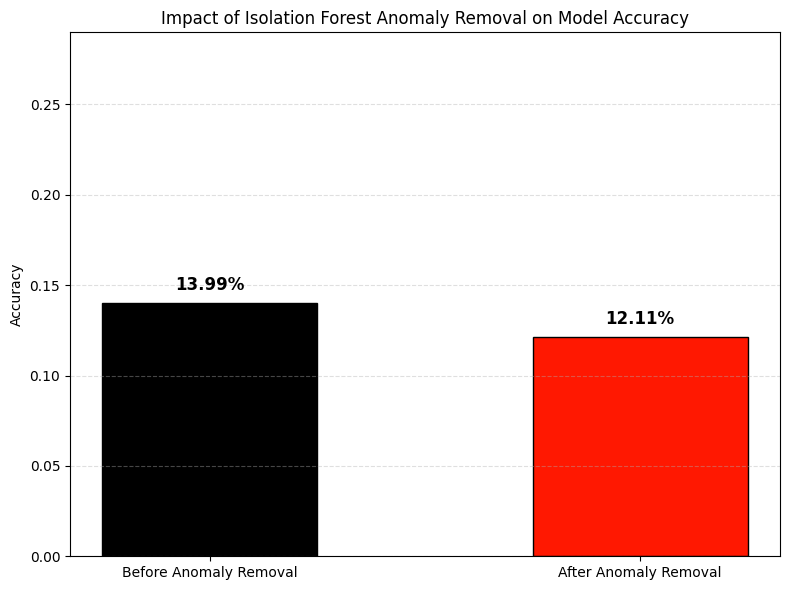

In [53]:
# --- Visualization 1: Bar Chart — Impact on Accuracy ---
f1_red  = '#FF1801'
f1_dark = '#000000'

plt.figure(figsize=(8, 6))
bars = plt.bar(
    ['Before Anomaly Removal', 'After Anomaly Removal'],
    [accuracy_baseline, accuracy_if],
    color=[f1_dark, f1_red], edgecolor='black', width=0.5
)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.005,
             f'{height:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylabel('Accuracy')
plt.title('Impact of Isolation Forest Anomaly Removal on Model Accuracy')
plt.ylim(0, min(max(accuracy_baseline, accuracy_if) + 0.15, 1.0))
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

The scatterplot confirms that the isolation forest identifies drivers whose qualifying and rid position don't align confirming that the algorithm is detecting anomalies (orange). 

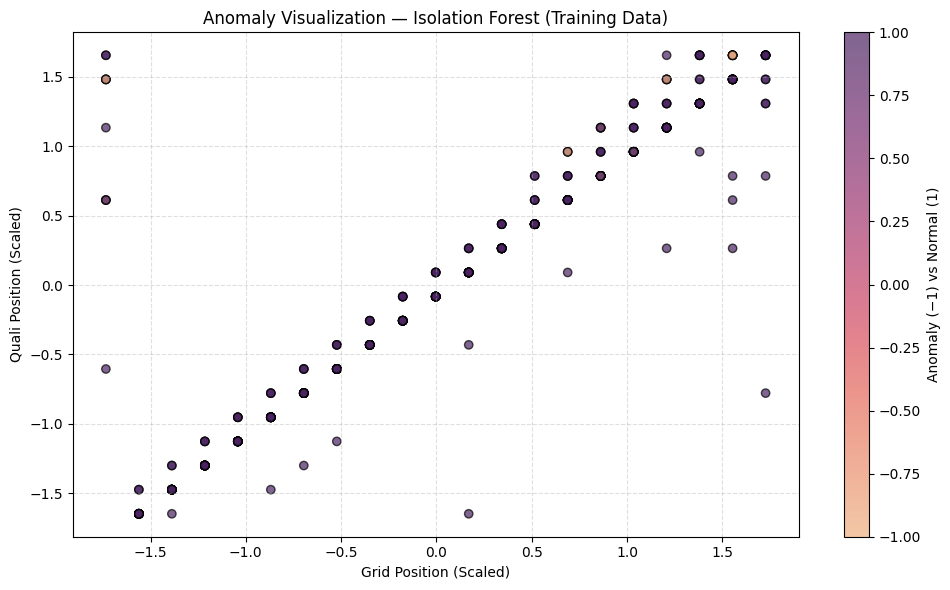

In [54]:
# --- Visualization 2: Scatter Plot — Anomaly Map ---
plt.figure(figsize=(10, 6))
plt.scatter(
    X_train['Grid Position'],
    X_train['Quali Position'],
    c=train_anomalies_if,
    cmap='flare',
    edgecolors='k',
    alpha=0.7
)
plt.xlabel('Grid Position (Scaled)')
plt.ylabel('Quali Position (Scaled)')
plt.title('Anomaly Visualization — Isolation Forest (Training Data)')
plt.colorbar(label='Anomaly (−1) vs Normal (1)')
plt.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Unlike HBOS which flagged driver-level outliers, Isolation Forest's anomalies are strongly driven by circuit geography — particularly high-altitude venues like Mexico City — where thinner air produces lap time patterns statistically unlike the rest of the calendar.

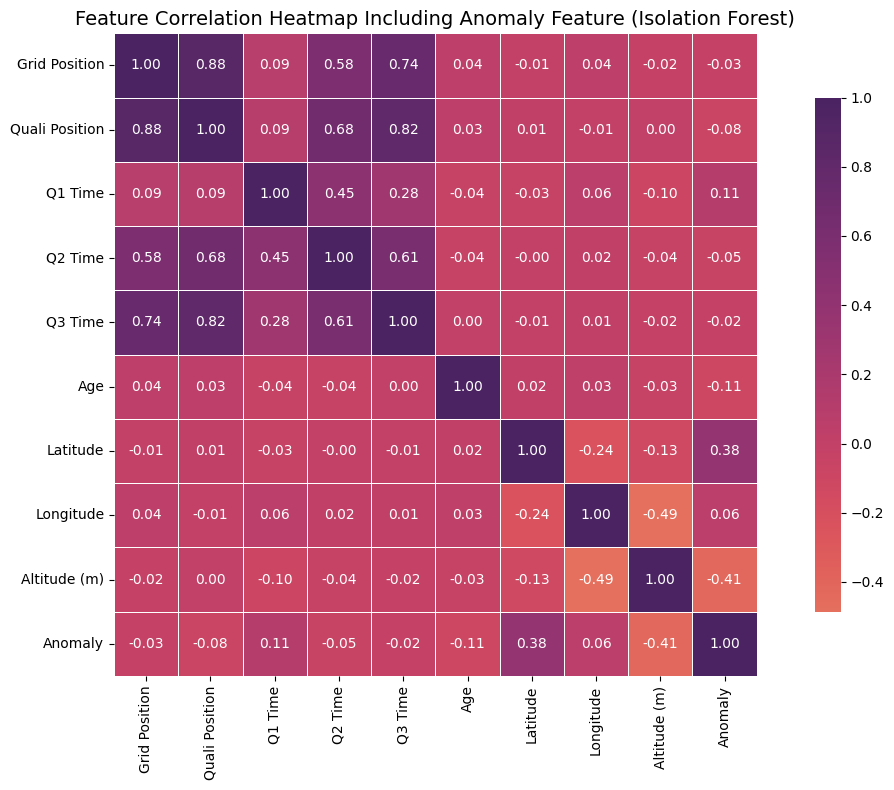

In [55]:
# --- Visualization 3: Correlation Heatmap including Anomaly column ---
X_train['Anomaly'] = train_anomalies_if

heatmap_features = [
    'Grid Position', 'Quali Position', 'Q1 Time', 'Q2 Time', 'Q3 Time',
    'Age', 'Latitude', 'Longitude', 'Altitude (m)', 'Anomaly'
]
heatmap_features = [f for f in heatmap_features if f in X_train.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(
    X_train[heatmap_features].corr(),
    annot=True, fmt='.2f',
    cmap='flare', center=0,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    square=True
)
plt.title('Feature Correlation Heatmap Including Anomaly Feature (Isolation Forest)', fontsize=14)
plt.tight_layout()
plt.show()

# Clean up so the Anomaly column doesn't interfere with anything below
X_train = X_train.drop(columns=['Anomaly'])

Looking at the density plot, we can see that the drivers flagged as anomalies tend to have much faster Q1 times than the rest of the field, which makes sense given that our heatmap showed Isolation Forest was mainly picking up on high-altitude circuits.

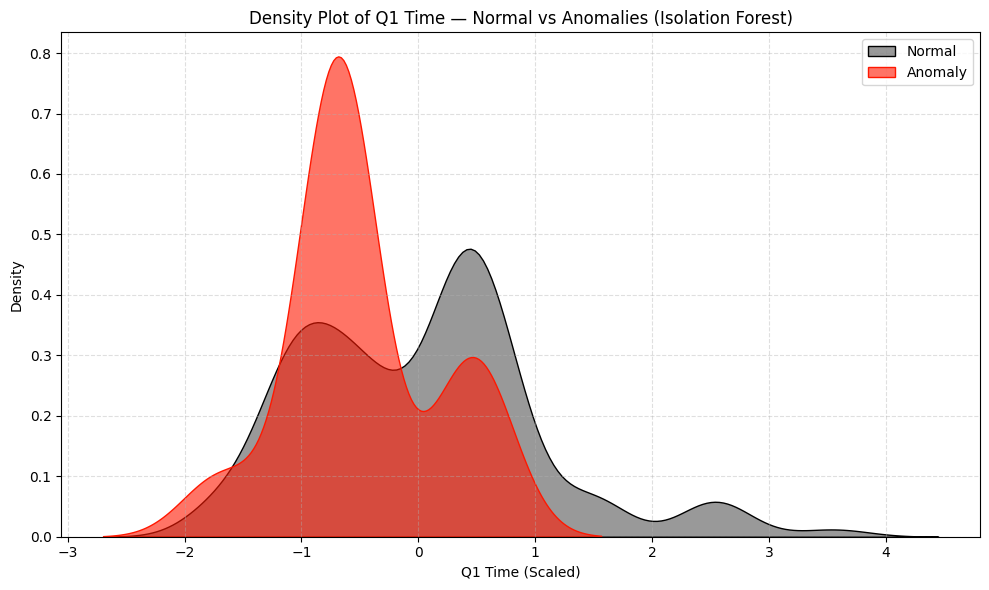

In [56]:
# --- Visualization 4: Density Plot — Normal vs Anomaly (Q1 Time) ---
X_train['Anomaly'] = train_anomalies_if

plt.figure(figsize=(10, 6))
sns.kdeplot(
    X_train.loc[X_train['Anomaly'] == 1,  'Q1 Time'],
    label='Normal', fill=True, color=f1_dark, alpha=0.4
)
sns.kdeplot(
    X_train.loc[X_train['Anomaly'] == -1, 'Q1 Time'],
    label='Anomaly', fill=True, color=f1_red, alpha=0.6
)
plt.title('Density Plot of Q1 Time — Normal vs Anomalies (Isolation Forest)')
plt.xlabel('Q1 Time (Scaled)')
plt.ylabel('Density')
plt.legend()
plt.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Clean up
X_train = X_train.drop(columns=['Anomaly'])

Side by side comparison of the baseline model and both the HBOS and Isolation Forest

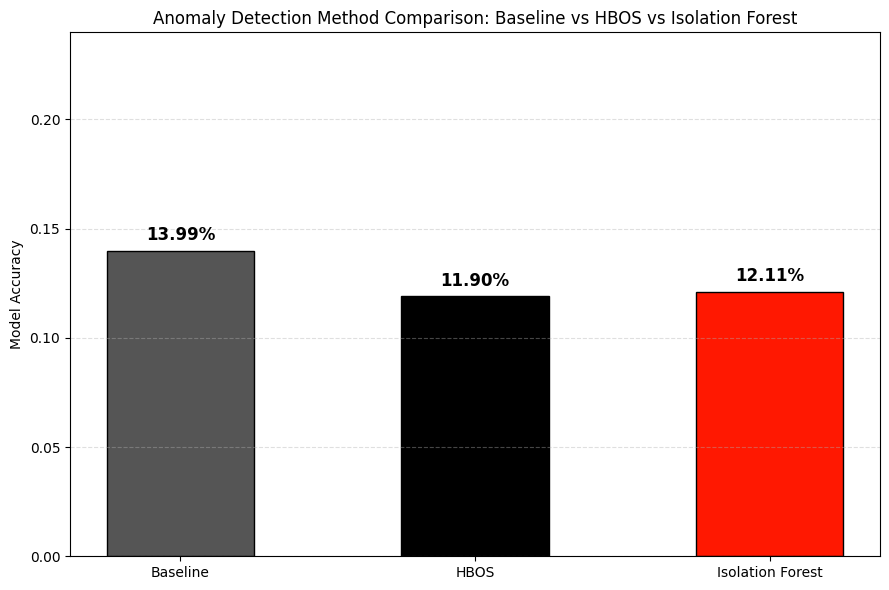

In [57]:
# --- Bonus: Side-by-side comparison — Baseline vs HBOS vs Isolation Forest ---
methods    = ['Baseline', 'HBOS', 'Isolation Forest']
accuracies = [accuracy_baseline, accuracy_filtered, accuracy_if]
colors_bar = ['#555555', f1_dark, f1_red]

plt.figure(figsize=(9, 6))
bars = plt.bar(methods, accuracies, color=colors_bar, edgecolor='black', width=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.003,
             f'{height:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylabel('Model Accuracy')
plt.title('Anomaly Detection Method Comparison: Baseline vs HBOS vs Isolation Forest')
plt.ylim(0, min(max(accuracies) + 0.1, 1.0))
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Anomaly removal did not improve accuracy, suggesting the outliers in F1 data are meaningful signal